# 01 — Data Analysis (EDA)
### Group 3 Capstone: Intelligent Fraud Detection Using Explainable ML

Loads the raw dataset, runs integrity checks, and produces the exploratory
plots that motivate the rest of the pipeline (class imbalance, feature
distributions, correlations).


In [1]:
# ---------------------------------------------------------------------------
# Make the src/ package importable from inside notebooks/, and fix all
# random seeds so this notebook is reproducible (Section 14 requirement).
# ---------------------------------------------------------------------------
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import preprocessing, features, models, evaluation, explainability

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (8, 4)


In [2]:
df = preprocessing.load_data("../data/raw/creditcard.csv")
df.head()


Loaded real dataset from ../data/raw/creditcard.csv: 284,807 rows, 31 columns


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
report = preprocessing.data_quality_report(df)
for k, v in report.items():
    print(f"{k}: {v}")


n_rows: 284807
n_missing_cells: 0
n_duplicate_rows: 1081
class_counts: {0: 284315, 1: 492}
fraud_rate_pct: 0.1727485630620034


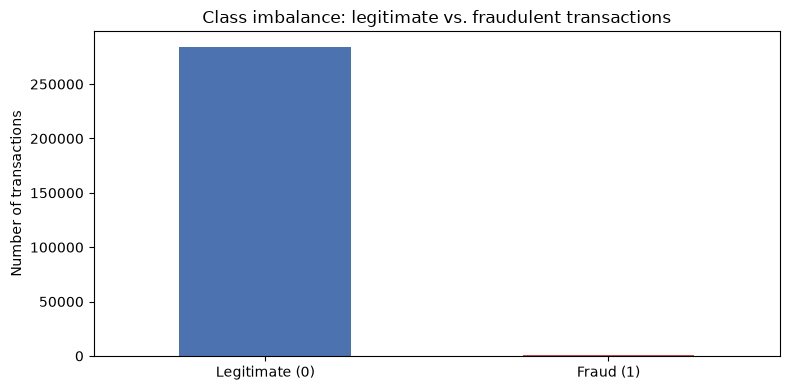

In [4]:
ax = pd.Series(report["class_counts"]).plot(kind="bar", color=["#4C72B0", "#C44E52"])
ax.set_xticklabels(["Legitimate (0)", "Fraud (1)"], rotation=0)
ax.set_ylabel("Number of transactions")
ax.set_title("Class imbalance: legitimate vs. fraudulent transactions")
plt.tight_layout()
plt.show()


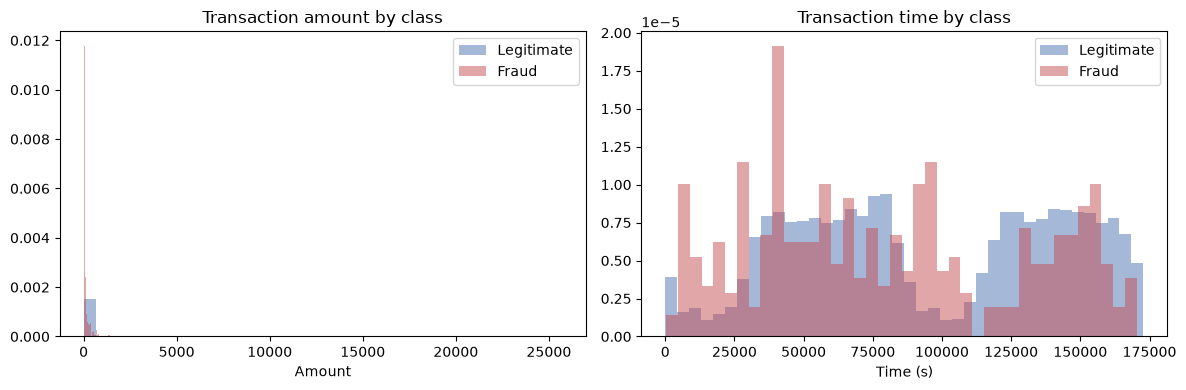

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for cls, label, color in [(0, "Legitimate", "#4C72B0"), (1, "Fraud", "#C44E52")]:
    subset = df[df["Class"] == cls]
    axes[0].hist(subset["Amount"], bins=40, alpha=0.5, label=label, color=color, density=True)
    axes[1].hist(subset["Time"], bins=40, alpha=0.5, label=label, color=color, density=True)
axes[0].set_title("Transaction amount by class"); axes[0].set_xlabel("Amount"); axes[0].legend()
axes[1].set_title("Transaction time by class"); axes[1].set_xlabel("Time (s)"); axes[1].legend()
plt.tight_layout(); plt.show()


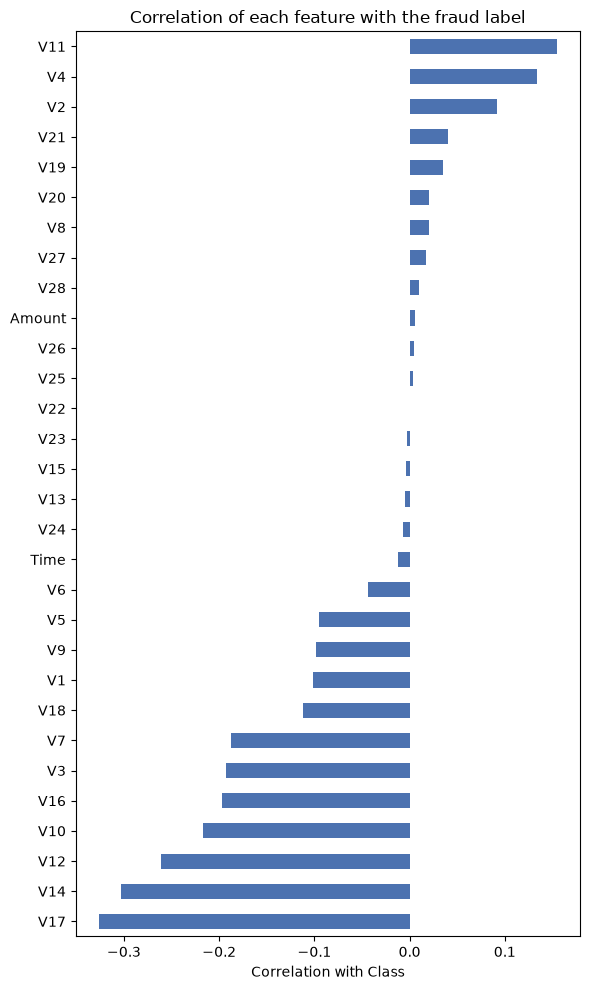

In [6]:
corr = df.corr(numeric_only=True)["Class"].drop("Class").sort_values()
plt.figure(figsize=(6, 10))
corr.plot(kind="barh", color="#4C72B0")
plt.title("Correlation of each feature with the fraud label")
plt.xlabel("Correlation with Class")
plt.tight_layout()
plt.show()


**Takeaways to carry into the report:** note the exact fraud rate printed
above, which features are most correlated with `Class` (candidates SHAP
should later confirm as important), and whether `Amount`/`Time` show a
visibly different distribution for fraud vs. legitimate transactions.
